In [5]:
import pandas as pd
import os

# Folder path
DATA_DIR = "api_data_aadhar_demographic/"

# Exact file list (order preserved)
files = [
    "api_data_aadhar_demographic_0_500000.csv",
    "api_data_aadhar_demographic_500000_1000000.csv",
    "api_data_aadhar_demographic_1000000_1500000.csv",
    "api_data_aadhar_demographic_1500000_2000000.csv",
    "api_data_aadhar_demographic_2000000_2071700.csv"
]

# Read and append
df_list = []

for file in files:
    path = os.path.join(DATA_DIR, file)
    temp_df = pd.read_csv(path)
    df_list.append(temp_df)

# Vertical merge (row-wise)
merged_df = pd.concat(df_list, axis=0, ignore_index=True)

print("Merged Dataset Shape:", merged_df.shape)
merged_df.head()


Merged Dataset Shape: (2071700, 6)


,date,state,district,pincode,demo_age_5_17,demo_age_17_
0,01-03-2025,Uttar Pradesh,Gorakhpur,273213,49,529
1,01-03-2025,Andhra Pradesh,Chittoor,517132,22,375
2,01-03-2025,Gujarat,Rajkot,360006,65,765
3,01-03-2025,Andhra Pradesh,Srikakulam,532484,24,314
4,01-03-2025,Rajasthan,Udaipur,313801,45,785


In [6]:
merged_df

,date,state,district,pincode,demo_age_5_17,demo_age_17_
0,01-03-2025,Uttar Pradesh,Gorakhpur,273213,49,529
1,01-03-2025,Andhra Pradesh,Chittoor,517132,22,375
2,01-03-2025,Gujarat,Rajkot,360006,65,765
3,01-03-2025,Andhra Pradesh,Srikakulam,532484,24,314
4,01-03-2025,Rajasthan,Udaipur,313801,45,785
...,...,...,...,...,...,...
2071695,29-12-2025,West Bengal,West Midnapore,721212,0,12
2071696,29-12-2025,West Bengal,West Midnapore,721420,0,1
2071697,29-12-2025,West Bengal,West Midnapore,721424,0,5
2071698,29-12-2025,West Bengal,West Midnapore,721426,0,3


In [7]:
output_path = "aadhaar_demographic_merged.csv"
merged_df.to_csv(output_path, index=False)

print("Merged file saved as:", output_path)

Merged file saved as: aadhaar_demographic_merged.csv


In [8]:
# Null check
merged_df.isnull().sum()

# Duplicate check
print("Duplicate rows:", merged_df.duplicated().sum())

# Date range check
print(merged_df['date'].min(), merged_df['date'].max())

Duplicate rows: 473601
01-03-2025 31-10-2025


In [9]:
# Load merged dataset
df = pd.read_csv("aadhaar_demographic_merged.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Convert date
df['date'] = pd.to_datetime(df['date'], format="%d-%m-%Y", errors='coerce')

# Convert demographic columns to numeric
df['demo_age_5_17'] = pd.to_numeric(df['demo_age_5_17'], errors='coerce')
df['demo_age_17_'] = pd.to_numeric(df['demo_age_17_'], errors='coerce')

# Fill missing values
df[['demo_age_5_17', 'demo_age_17_']] = df[['demo_age_5_17', 'demo_age_17_']].fillna(0)

# Create total updates column
df['total_updates'] = df['demo_age_5_17'] + df['demo_age_17_']

# Standardize text fields
df['state'] = df['state'].str.title().str.strip()
df['district'] = df['district'].str.title().str.strip()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2071700 entries, 0 to 2071699
Data columns (total 7 columns):
 #   Column         Dtype         
---  ------         -----         
 0   date           datetime64[ns]
 1   state          object        
 2   district       object        
 3   pincode        int64         
 4   demo_age_5_17  int64         
 5   demo_age_17_   int64         
 6   total_updates  int64         
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 110.6+ MB


In [10]:
state_summary = (
    df.groupby('state')['total_updates']
    .sum()
    .reset_index()
    .sort_values(by='total_updates', ascending=False)
)

state_summary.head(10)

,state,total_updates
50,Uttar Pradesh,8542328
32,Maharashtra,5054602
7,Bihar,4814350
55,West Bengal,3872318
31,Madhya Pradesh,2912938
45,Rajasthan,2817615
3,Andhra Pradesh,2295582
47,Tamil Nadu,2212228
10,Chhattisgarh,2005434
19,Gujarat,1824327


In [11]:
district_summary = (
    df.groupby(['state', 'district'])['total_updates']
    .sum()
    .reset_index()
    .sort_values(by='total_updates', ascending=False)
)

# Top 15 high-activity districts
top_districts = district_summary.head(10)
top_districts

,state,district,total_updates
560,Maharashtra,Thane,447253
551,Maharashtra,Pune,438478
1036,West Bengal,South 24 Parganas,401187
1022,West Bengal,Murshidabad,371953
264,Gujarat,Surat,357582
221,Delhi,North West Delhi,313989
388,Karnataka,Bengaluru,303924
1025,West Bengal,North 24 Parganas,290477
756,Rajasthan,Jaipur,275340
1040,West Bengal,Uttar Dinajpur,270232


In [12]:
print("Total Records:", len(df))
print("Total States:", df['state'].nunique())
print("Total Districts:", df['district'].nunique())

Total Records: 2071700
Total States: 58
Total Districts: 961


In [13]:
df.describe()

,date,pincode,demo_age_5_17,demo_age_17_,total_updates
count,2071700,2.071700e+06,2.071700e+06,2.071700e+06,2.071700e+06
mean,2025-11-02 19:25:06.470626304,5.278318e+05,2.347552e+00,2.144701e+01,2.379456e+01
min,2025-03-01 00:00:00,1.000000e+05,0.000000e+00,0.000000e+00,0.000000e+00
25%,2025-10-15 00:00:00,3.964690e+05,0.000000e+00,2.000000e+00,3.000000e+00
50%,2025-11-08 00:00:00,5.243220e+05,1.000000e+00,6.000000e+00,7.000000e+00
75%,2025-12-06 00:00:00,6.955070e+05,2.000000e+00,1.500000e+01,1.700000e+01
max,2025-12-29 00:00:00,8.554560e+05,2.690000e+03,1.616600e+04,1.694200e+04
std,NaN,1.972933e+05,1.490355e+01,1.252498e+02,1.381999e+02


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8860\4086783827.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


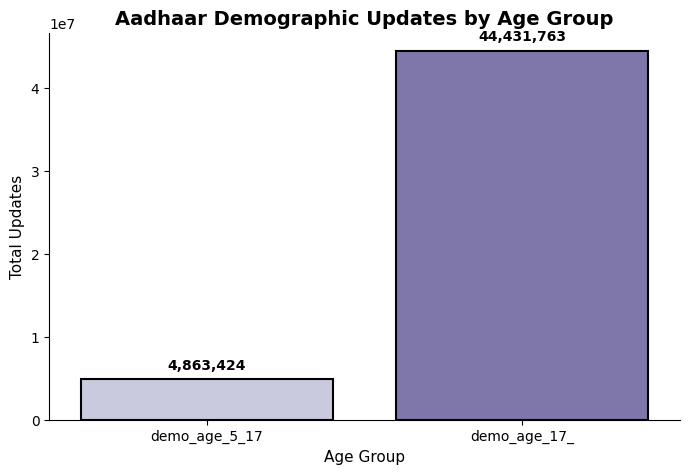

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

age_group_totals = df[['demo_age_5_17', 'demo_age_17_']].sum()

plt.figure(figsize=(7,5))

ax = sns.barplot(
    x=age_group_totals.index,
    y=age_group_totals.values,
    palette="Purples",
    edgecolor="black",
    linewidth=1.5
)

# Title & labels
plt.title(
    "Aadhaar Demographic Updates by Age Group",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Age Group", fontsize=11)
plt.ylabel("Total Updates", fontsize=11)

# Add value labels on top of bars
max_value = age_group_totals.max()
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02 * max_value,   # small vertical offset
        f'{int(height):,}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

sns.despine()
plt.tight_layout()
plt.show()


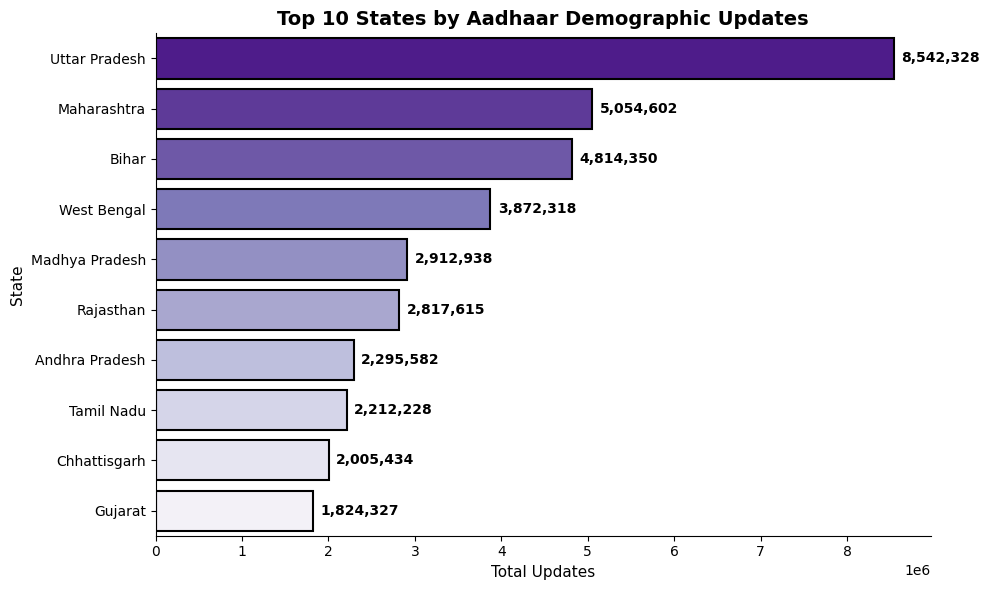

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

ax = sns.barplot(
    y=state_summary.index,
    x=state_summary.values,
    edgecolor="black",
    linewidth=1.5
)

# Apply dark → light purple gradient manually
colors = sns.color_palette("Purples", n_colors=len(state_summary))[::-1]
for bar, color in zip(ax.patches, colors):
    bar.set_facecolor(color)

# Title & labels (unchanged)
plt.title("Top 10 States by Aadhaar Demographic Updates", fontsize=14, fontweight="bold")
plt.xlabel("Total Updates", fontsize=11)
plt.ylabel("State", fontsize=11)

# Add value labels
max_value = state_summary.max()
for bar in ax.patches:
    width = bar.get_width()
    ax.text(
        width + 0.01 * max_value,   # small offset to the right
        bar.get_y() + bar.get_height() / 2,
        f'{int(width):,}',
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold'
    )

sns.despine()
plt.tight_layout()
plt.show()


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8860\1665553517.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


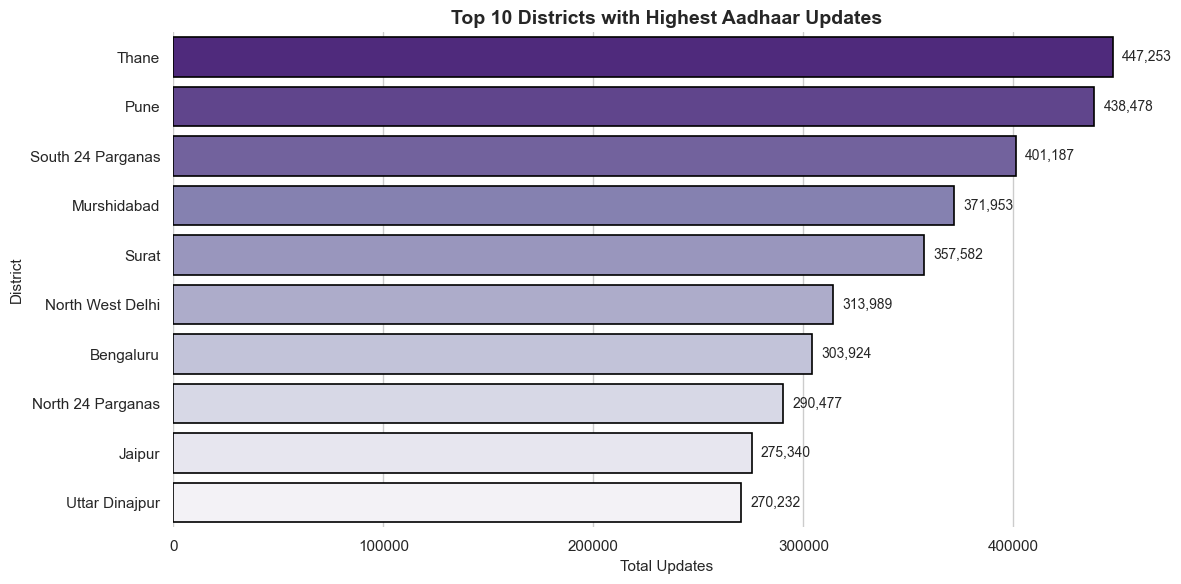

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

district_summary = (
    df.groupby(['state', 'district'])['total_updates']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Create gradient: dark → light
colors = sns.color_palette("Purples_r", n_colors=len(district_summary))
# _r reverses palette so highest value is darkest

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=district_summary.values,
    y=district_summary.index.get_level_values('district'),
    palette=colors,
    edgecolor="black",
    linewidth=1.2
)

# Titles & labels
plt.title("Top 10 Districts with Highest Aadhaar Updates",
          fontsize=14, fontweight="bold")
plt.xlabel("Total Updates", fontsize=11)
plt.ylabel("District", fontsize=11)

# Add value labels
max_val = district_summary.max()
for i, value in enumerate(district_summary.values):
    ax.text(
        value + 0.01 * max_val,
        i,
        f"{value:,}",
        va="center",
        fontsize=10
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


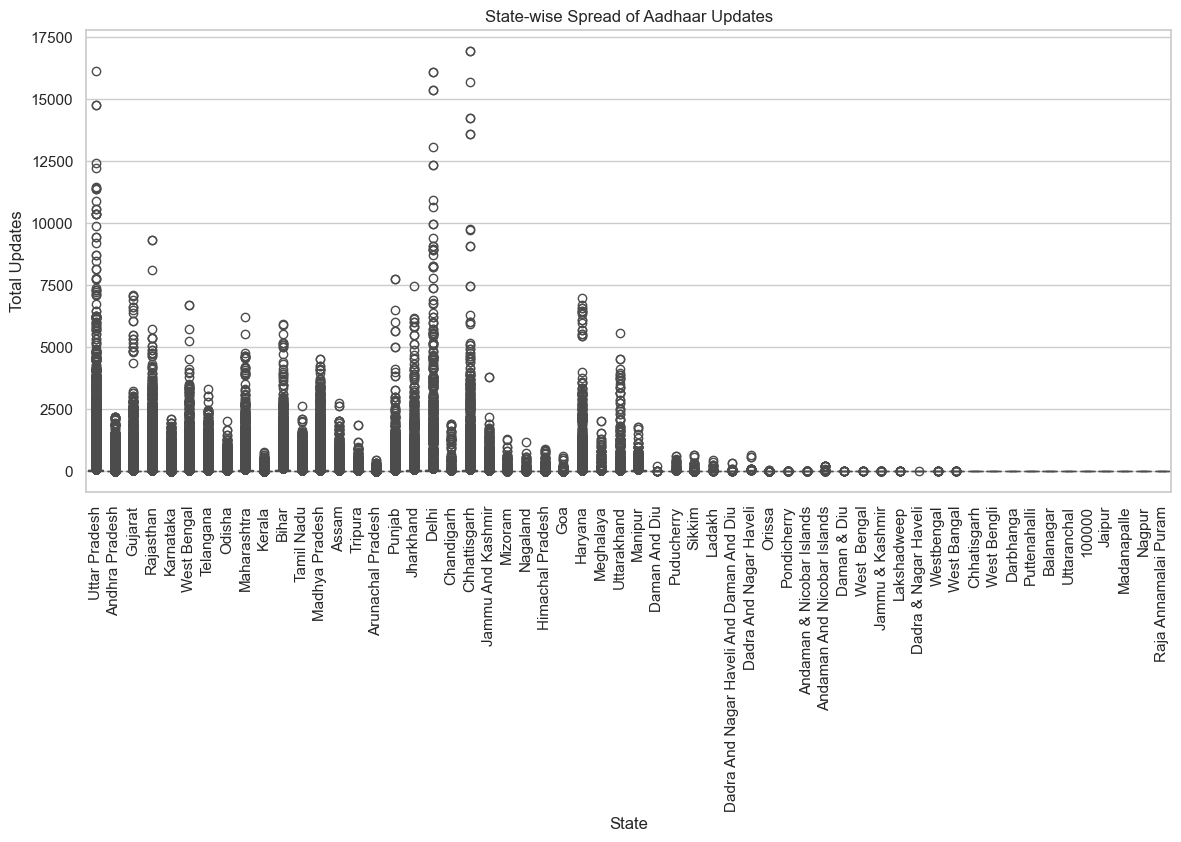

In [28]:
plt.figure(figsize=(14,6))
sns.boxplot(
    x='state',
    y='total_updates',
    data=df
)

plt.xticks(rotation=90)
plt.title("State-wise Spread of Aadhaar Updates")
plt.xlabel("State")
plt.ylabel("Total Updates")
plt.show()

In [29]:
states_list = sorted(df['state'].dropna().unique())

print("Total States:", len(states_list))
print("List of States:")
for state in states_list:
    print(state)

Total States: 58
List of States:
100000
Andaman & Nicobar Islands
Andaman And Nicobar Islands
Andhra Pradesh
Arunachal Pradesh
Assam
Balanagar
Bihar
Chandigarh
Chhatisgarh
Chhattisgarh
Dadra & Nagar Haveli
Dadra And Nagar Haveli
Dadra And Nagar Haveli And Daman And Diu
Daman & Diu
Daman And Diu
Darbhanga
Delhi
Goa
Gujarat
Haryana
Himachal Pradesh
Jaipur
Jammu & Kashmir
Jammu And Kashmir
Jharkhand
Karnataka
Kerala
Ladakh
Lakshadweep
Madanapalle
Madhya Pradesh
Maharashtra
Manipur
Meghalaya
Mizoram
Nagaland
Nagpur
Odisha
Orissa
Pondicherry
Puducherry
Punjab
Puttenahalli
Raja Annamalai Puram
Rajasthan
Sikkim
Tamil Nadu
Telangana
Tripura
Uttar Pradesh
Uttarakhand
Uttaranchal
West  Bengal
West Bangal
West Bengal
West Bengli
Westbengal


In [30]:
state_mapping = {
    # Andaman & Nicobar
    "Andaman & Nicobar Islands": "Andaman And Nicobar Islands",
    "Andaman And Nicobar Islands": "Andaman And Nicobar Islands",

    # Andhra Pradesh
    "Andhra Pradesh": "Andhra Pradesh",
    "Madanapalle": "Andhra Pradesh",

    # Arunachal Pradesh
    "Arunachal Pradesh": "Arunachal Pradesh",

    # Assam
    "Assam": "Assam",

    # Bihar
    "Bihar": "Bihar",
    "Darbhanga": "Bihar",

    # Chandigarh
    "Chandigarh": "Chandigarh",

    # Chhattisgarh
    "Chhatisgarh": "Chhattisgarh",
    "Chhattisgarh": "Chhattisgarh",

    # Dadra & Nagar Haveli / Daman & Diu (Merged UT)
    "Dadra & Nagar Haveli": "Dadra And Nagar Haveli And Daman And Diu",
    "Dadra And Nagar Haveli": "Dadra And Nagar Haveli And Daman And Diu",
    "Daman & Diu": "Dadra And Nagar Haveli And Daman And Diu",
    "Daman And Diu": "Dadra And Nagar Haveli And Daman And Diu",
    "Dadra And Nagar Haveli And Daman And Diu": "Dadra And Nagar Haveli And Daman And Diu",

    # Delhi
    "Delhi": "Delhi",

    # Goa
    "Goa": "Goa",

    # Gujarat
    "Gujarat": "Gujarat",

    # Haryana
    "Haryana": "Haryana",

    # Himachal Pradesh
    "Himachal Pradesh": "Himachal Pradesh",

    # Rajasthan
    "Rajasthan": "Rajasthan",
    "Jaipur": "Rajasthan",

    # Jammu & Kashmir
    "Jammu & Kashmir": "Jammu And Kashmir",
    "Jammu And Kashmir": "Jammu And Kashmir",

    # Jharkhand
    "Jharkhand": "Jharkhand",

    # Karnataka
    "Karnataka": "Karnataka",
    "Balanagar": "Karnataka",
    "Puttenahalli": "Karnataka",
    "Raja Annamalai Puram": "Karnataka",

    # Kerala
    "Kerala": "Kerala",

    # Ladakh
    "Ladakh": "Ladakh",

    # Lakshadweep
    "Lakshadweep": "Lakshadweep",

    # Madhya Pradesh
    "Madhya Pradesh": "Madhya Pradesh",

    # Maharashtra
    "Maharashtra": "Maharashtra",
    "Nagpur": "Maharashtra",

    # Manipur
    "Manipur": "Manipur",

    # Meghalaya
    "Meghalaya": "Meghalaya",

    # Mizoram
    "Mizoram": "Mizoram",

    # Nagaland
    "Nagaland": "Nagaland",

    # Odisha
    "Odisha": "Odisha",
    "Orissa": "Odisha",

    # Puducherry
    "Pondicherry": "Puducherry",
    "Puducherry": "Puducherry",

    # Punjab
    "Punjab": "Punjab",

    # Sikkim
    "Sikkim": "Sikkim",

    # Tamil Nadu
    "Tamil Nadu": "Tamil Nadu",

    # Telangana
    "Telangana": "Telangana",

    # Tripura
    "Tripura": "Tripura",

    # Uttar Pradesh
    "Uttar Pradesh": "Uttar Pradesh",

    # Uttarakhand
    "Uttarakhand": "Uttarakhand",
    "Uttaranchal": "Uttarakhand",

    # West Bengal
    "West Bengal": "West Bengal",
    "West  Bengal": "West Bengal",
    "West Bangal": "West Bengal",
    "West Bengli": "West Bengal",
    "Westbengal": "West Bengal"
}


In [31]:
# Create a copy (original df is preserved)
df_clean = df.copy()

# Apply state normalization
df_clean['state_clean'] = df_clean['state'].map(state_mapping)

# If any state is not mapped, keep original
df_clean['state_clean'] = df_clean['state_clean'].fillna(df_clean['state'])

df_clean.head()

,date,state,district,pincode,demo_age_5_17,demo_age_17_,total_updates,state_clean
0,2025-03-01,Uttar Pradesh,Gorakhpur,273213,49,529,578,Uttar Pradesh
1,2025-03-01,Andhra Pradesh,Chittoor,517132,22,375,397,Andhra Pradesh
2,2025-03-01,Gujarat,Rajkot,360006,65,765,830,Gujarat
3,2025-03-01,Andhra Pradesh,Srikakulam,532484,24,314,338,Andhra Pradesh
4,2025-03-01,Rajasthan,Udaipur,313801,45,785,830,Rajasthan


In [32]:
df_clean

,date,state,district,pincode,demo_age_5_17,demo_age_17_,total_updates,state_clean
0,2025-03-01,Uttar Pradesh,Gorakhpur,273213,49,529,578,Uttar Pradesh
1,2025-03-01,Andhra Pradesh,Chittoor,517132,22,375,397,Andhra Pradesh
2,2025-03-01,Gujarat,Rajkot,360006,65,765,830,Gujarat
3,2025-03-01,Andhra Pradesh,Srikakulam,532484,24,314,338,Andhra Pradesh
4,2025-03-01,Rajasthan,Udaipur,313801,45,785,830,Rajasthan
...,...,...,...,...,...,...,...,...
2071695,2025-12-29,West Bengal,West Midnapore,721212,0,12,12,West Bengal
2071696,2025-12-29,West Bengal,West Midnapore,721420,0,1,1,West Bengal
2071697,2025-12-29,West Bengal,West Midnapore,721424,0,5,5,West Bengal
2071698,2025-12-29,West Bengal,West Midnapore,721426,0,3,3,West Bengal


In [33]:
print("Original unique states:", df['state'].nunique())
print("Cleaned unique states:", df_clean['state_clean'].nunique())

Original unique states: 58
Cleaned unique states: 37


In [34]:
clean_states = sorted(df_clean['state_clean'].unique())

print("Final Standardized States:")
for state in clean_states:
    print(state)

Final Standardized States:
100000
Andaman And Nicobar Islands
Andhra Pradesh
Arunachal Pradesh
Assam
Bihar
Chandigarh
Chhattisgarh
Dadra And Nagar Haveli And Daman And Diu
Delhi
Goa
Gujarat
Haryana
Himachal Pradesh
Jammu And Kashmir
Jharkhand
Karnataka
Kerala
Ladakh
Lakshadweep
Madhya Pradesh
Maharashtra
Manipur
Meghalaya
Mizoram
Nagaland
Odisha
Puducherry
Punjab
Rajasthan
Sikkim
Tamil Nadu
Telangana
Tripura
Uttar Pradesh
Uttarakhand
West Bengal


In [35]:
df_clean.groupby('state_clean')['total_updates'] \
        .sum() \
        .sort_values(ascending=False)

state_clean
Uttar Pradesh                               8542328
Maharashtra                                 5054603
Bihar                                       4814352
West Bengal                                 3872737
Madhya Pradesh                              2912938
Rajasthan                                   2817617
Andhra Pradesh                              2295584
Tamil Nadu                                  2212228
Chhattisgarh                                2005438
Gujarat                                     1824327
Karnataka                                   1695289
Telangana                                   1629908
Delhi                                       1438934
Jharkhand                                   1401189
Haryana                                     1166140
Odisha                                      1112065
Assam                                       1012578
Punjab                                       881895
Kerala                                       744952


In [36]:
df_clean[df_clean['state_clean'] == '100000']

,date,state,district,pincode,demo_age_5_17,demo_age_17_,total_updates,state_clean
795161,2025-12-23,100000,100000,100000,0,1,1,100000
2007370,2025-12-20,100000,100000,100000,0,1,1,100000


In [37]:
df_clean = df_clean[df_clean['state_clean'] != '100000']

In [38]:
df_clean = df_clean.reset_index(drop=True)

In [39]:
print("Remaining unique states:")
print(sorted(df_clean['state_clean'].unique()))


Remaining unique states:
['Andaman And Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra And Nagar Haveli And Daman And Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu And Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


In [40]:
remaining_states = sorted(df_clean['state_clean'].unique())
print("Remaining unique states:")
print(remaining_states)
print("Total number of unique states:", len(remaining_states))

Remaining unique states:
['Andaman And Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra And Nagar Haveli And Daman And Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu And Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']
Total number of unique states: 36


In [41]:
df_clean.groupby('state_clean')['total_updates'] \
        .sum() \
        .sort_values(ascending=False)

state_clean
Uttar Pradesh                               8542328
Maharashtra                                 5054603
Bihar                                       4814352
West Bengal                                 3872737
Madhya Pradesh                              2912938
Rajasthan                                   2817617
Andhra Pradesh                              2295584
Tamil Nadu                                  2212228
Chhattisgarh                                2005438
Gujarat                                     1824327
Karnataka                                   1695289
Telangana                                   1629908
Delhi                                       1438934
Jharkhand                                   1401189
Haryana                                     1166140
Odisha                                      1112065
Assam                                       1012578
Punjab                                       881895
Kerala                                       744952


In [42]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [43]:
df_clean

,date,state,district,pincode,demo_age_5_17,demo_age_17_,total_updates,state_clean
0,2025-03-01,Uttar Pradesh,Gorakhpur,273213,49,529,578,Uttar Pradesh
1,2025-03-01,Andhra Pradesh,Chittoor,517132,22,375,397,Andhra Pradesh
2,2025-03-01,Gujarat,Rajkot,360006,65,765,830,Gujarat
3,2025-03-01,Andhra Pradesh,Srikakulam,532484,24,314,338,Andhra Pradesh
4,2025-03-01,Rajasthan,Udaipur,313801,45,785,830,Rajasthan
...,...,...,...,...,...,...,...,...
2071693,2025-12-29,West Bengal,West Midnapore,721212,0,12,12,West Bengal
2071694,2025-12-29,West Bengal,West Midnapore,721420,0,1,1,West Bengal
2071695,2025-12-29,West Bengal,West Midnapore,721424,0,5,5,West Bengal
2071696,2025-12-29,West Bengal,West Midnapore,721426,0,3,3,West Bengal


In [44]:
state_summary = (
    df_clean
    .groupby('state_clean')['total_updates']
    .sum()
    .reset_index()
)

In [60]:
shapefile_path = "C:/Users/ASUS/OneDrive/Documents/Desktop/Aanchal/india/IND_adm1.shp"

india_states = gpd.read_file(shapefile_path)

# Inspect columns once (you already did, safe to keep)
print(india_states.columns)

Index(['ID_0', 'ISO', 'NAME_0', 'ID_1', 'NAME_1', 'VARNAME_1', 'NL_NAME_1',
       'HASC_1', 'CC_1', 'TYPE_1', 'ENGTYPE_1', 'VALIDFR_1', 'VALIDTO_1',
       'REMARKS_1', 'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='object')


In [61]:
india_states['state_shp'] = india_states['NAME_1'].str.title().str.strip()

In [62]:
# Ensure state_clean exists and is clean
df_clean['state_clean'] = df_clean['state_clean'].str.title().str.strip()

# Aggregate Aadhaar updates state-wise
state_summary = (
    df_clean
    .groupby('state_clean')['total_updates']
    .sum()
    .reset_index()
)

In [63]:
india_merged = india_states.merge(
    state_summary,
    how='left',
    left_on='state_shp',
    right_on='state_clean'
)

# Fill missing values
india_merged['total_updates'] = india_merged['total_updates'].fillna(0)

In [64]:
print("States in shapefile:", india_states['state_shp'].nunique())
print("States with Aadhaar data:", india_merged[india_merged['total_updates'] > 0]['state_shp'].nunique())

# Check which states didn't match (if any)
unmatched = india_merged[india_merged['total_updates'] == 0]['state_shp'].unique()
print("Unmatched / Zero-data states:", unmatched)

States in shapefile: 35
States with Aadhaar data: 30
Unmatched / Zero-data states: ['Andaman And Nicobar' 'Dadra And Nagar Haveli' 'Daman And Diu' 'Orissa'
 'Uttaranchal']


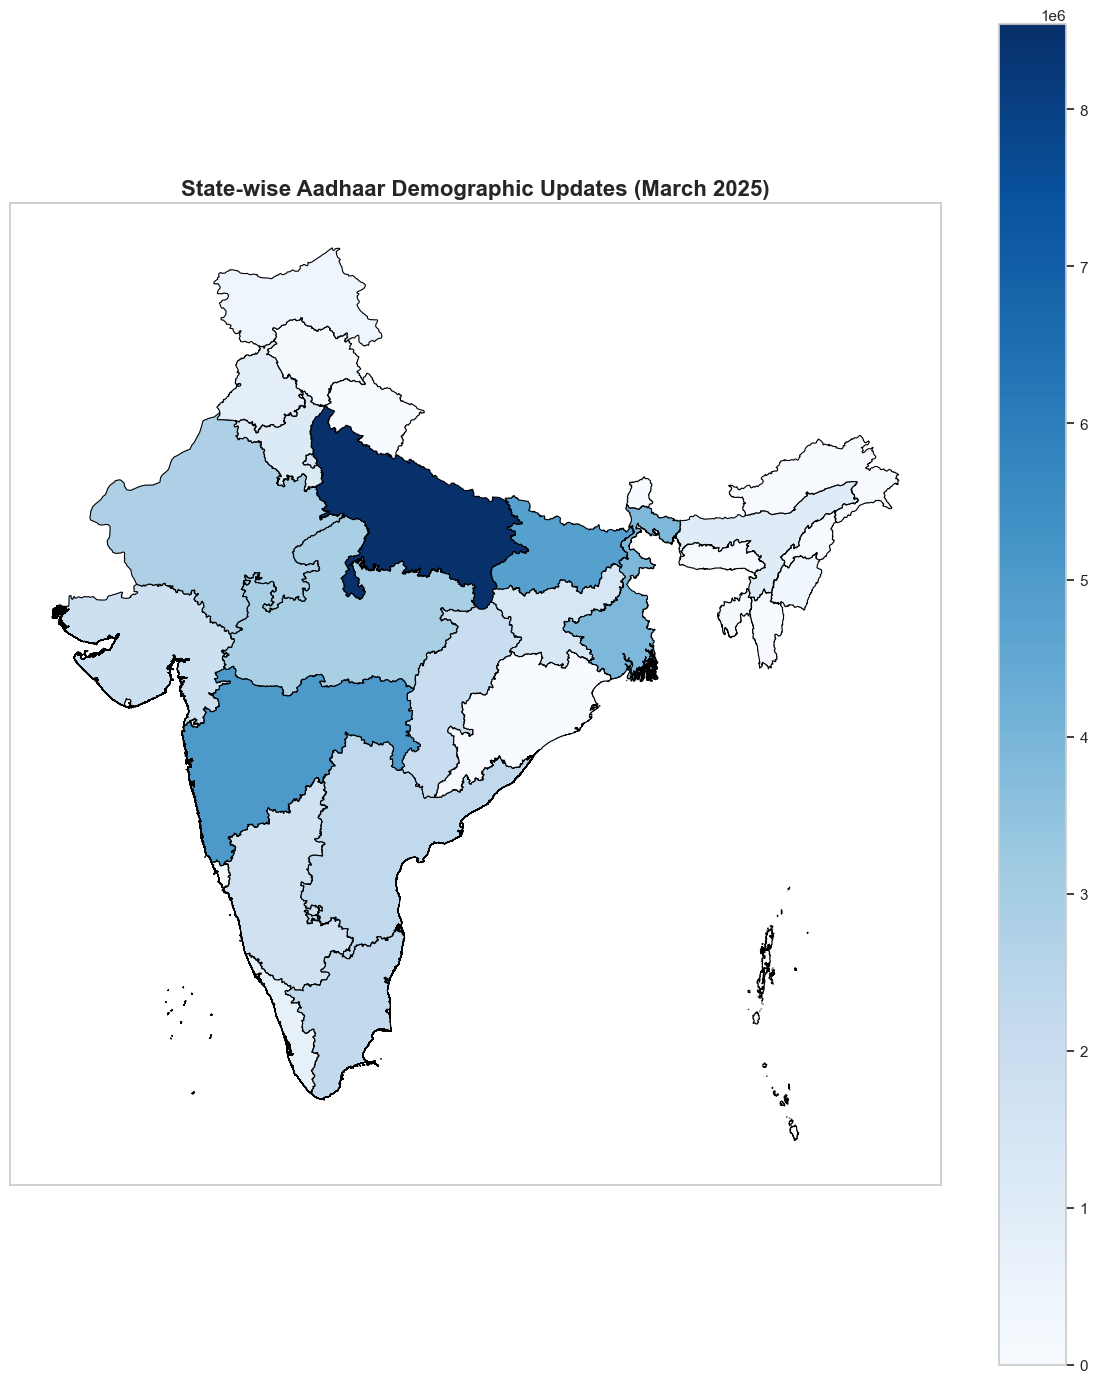

In [66]:
fig, ax = plt.subplots(figsize=(12, 14))

india_merged.plot(
    column='total_updates',
    cmap='Blues',          
    linewidth=0.8,
    edgecolor='black',
    legend=True,
    ax=ax
)

ax.set_title(
    "State-wise Aadhaar Demographic Updates (March 2025)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()


In [67]:
# Create state-wise dataframe for analysis
state_plot_df = india_merged[['state_shp', 'total_updates']].copy()

# Rename columns for clarity
state_plot_df.columns = ['state', 'total_updates']

# Sort in ascending order
state_plot_df = state_plot_df.sort_values(by='total_updates', ascending=False)

# Reset index
state_plot_df = state_plot_df.reset_index(drop=True)

# Display dataframe
state_plot_df

,state,total_updates
0,Uttar Pradesh,8542328.0
1,Maharashtra,5054603.0
2,Bihar,4814352.0
3,West Bengal,3872737.0
4,Madhya Pradesh,2912938.0
5,Rajasthan,2817617.0
6,Andhra Pradesh,2295584.0
7,Tamil Nadu,2212228.0
8,Chhattisgarh,2005438.0
9,Gujarat,1824327.0


In [68]:
state_plot_df[state_plot_df['state'] == 'Maharashtra']

,state,total_updates
1,Maharashtra,5054603.0


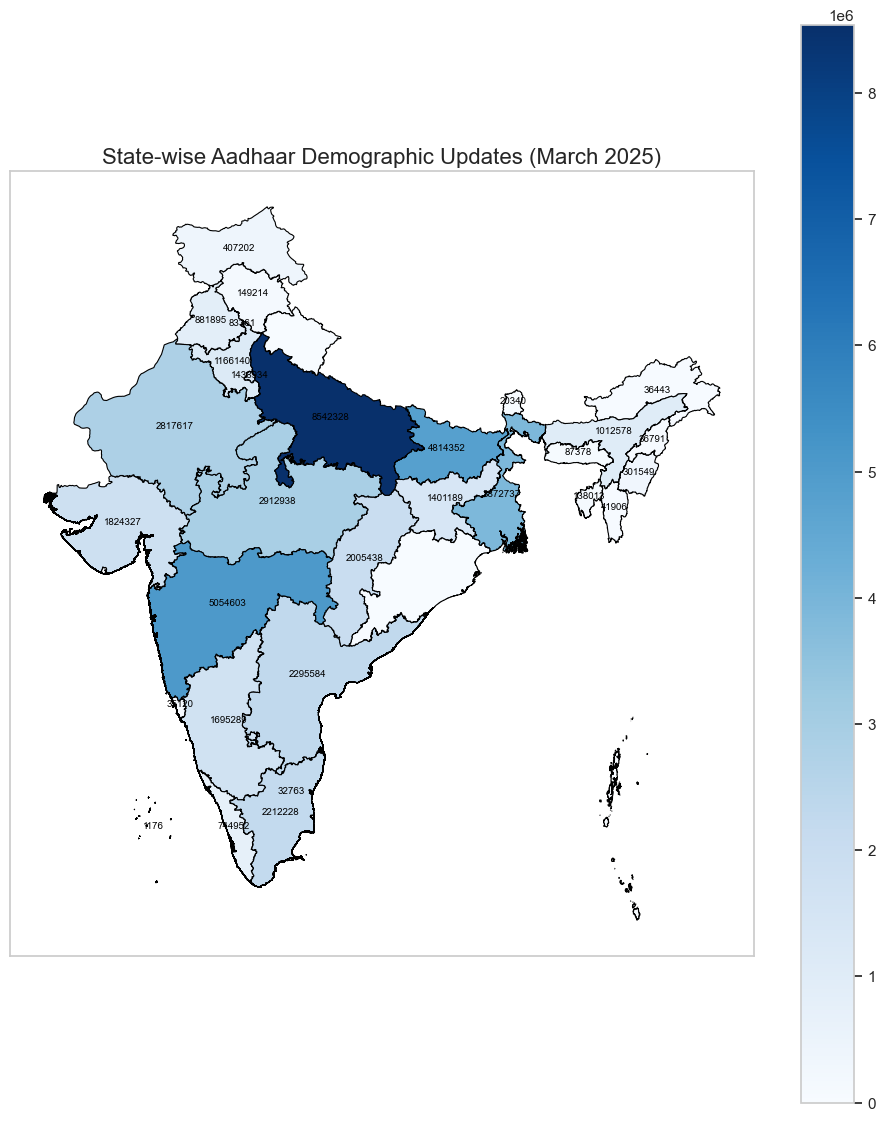

In [69]:

fig, ax = plt.subplots(figsize=(12, 14))

india_merged.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='black',
    legend=True,
    ax=ax
)

ax.set_title(
    "State-wise Aadhaar Demographic Updates (March 2025)",
    fontsize=16
)

ax.set_xticks([])
ax.set_yticks([])

# ---- ADD VALUE LABELS ON MAP ----
for idx, row in india_merged.iterrows():
    if row['total_updates'] > 0:
        ax.text(
            row.geometry.centroid.x,
            row.geometry.centroid.y,
            f"{int(row['total_updates'])}",
            horizontalalignment='center',
            fontsize=7,
            color='black'
        )

plt.show()

In [70]:
# States with zero Aadhaar updates after merge
missing_states_df = india_merged[india_merged['total_updates'] == 0][
    ['state_shp', 'total_updates']
].copy()

# Sort alphabetically for easy inspection
missing_states_df = missing_states_df.sort_values(by='state_shp').reset_index(drop=True)

print("States NOT displayed in choropleth (zero data):")
print(missing_states_df)

print("Count of missing states:", len(missing_states_df))

States NOT displayed in choropleth (zero data):
                state_shp  total_updates
0     Andaman And Nicobar            0.0
1  Dadra And Nagar Haveli            0.0
2           Daman And Diu            0.0
3                  Orissa            0.0
4             Uttaranchal            0.0
Count of missing states: 5


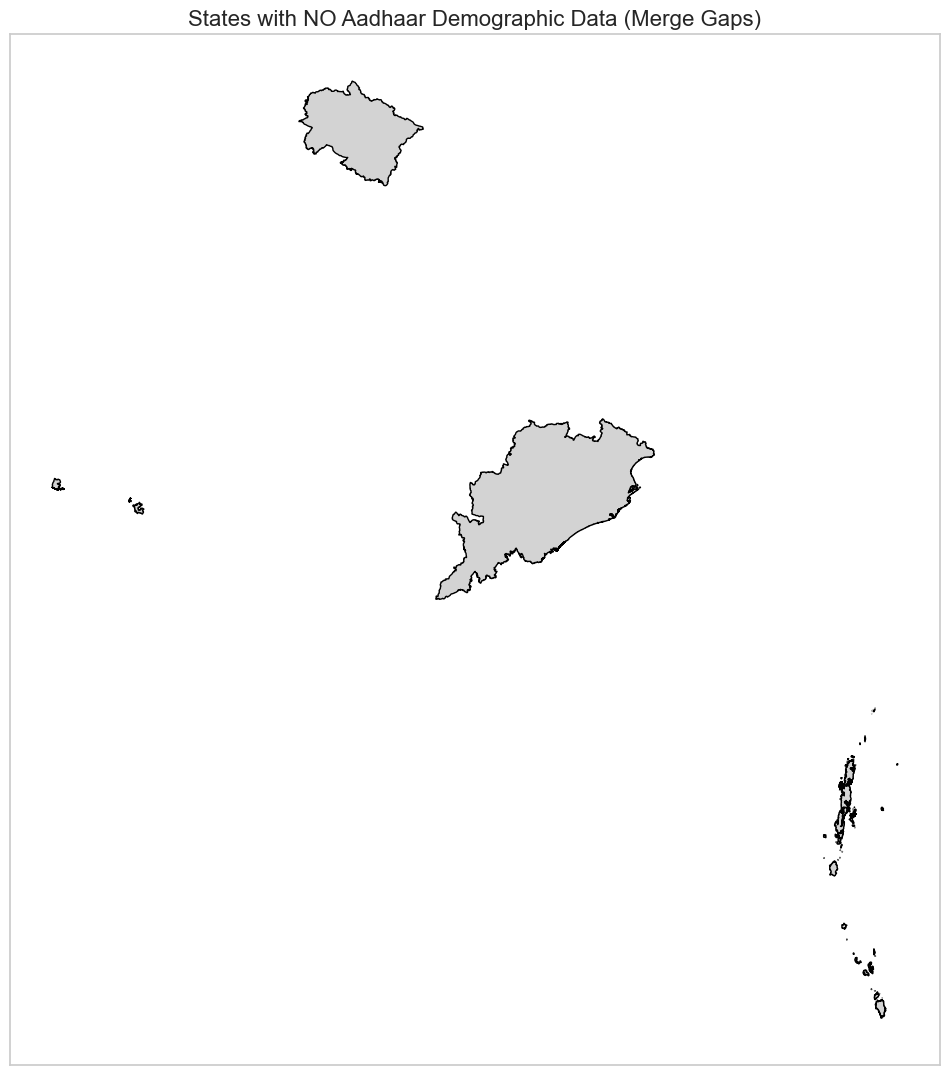

In [72]:
fig, ax = plt.subplots(figsize=(12, 14))

# Plot only missing states
india_merged[india_merged['total_updates'] == 0].plot(
    ax=ax,
    color='lightgrey',
    edgecolor='black'
)

ax.set_title(
    "States with NO Aadhaar Demographic Data (Merge Gaps)",
    fontsize=16
)

ax.set_xticks([])
ax.set_yticks([])

plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_8860\849267954.py:45: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='lower left')
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8860\849267954.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='lower left')


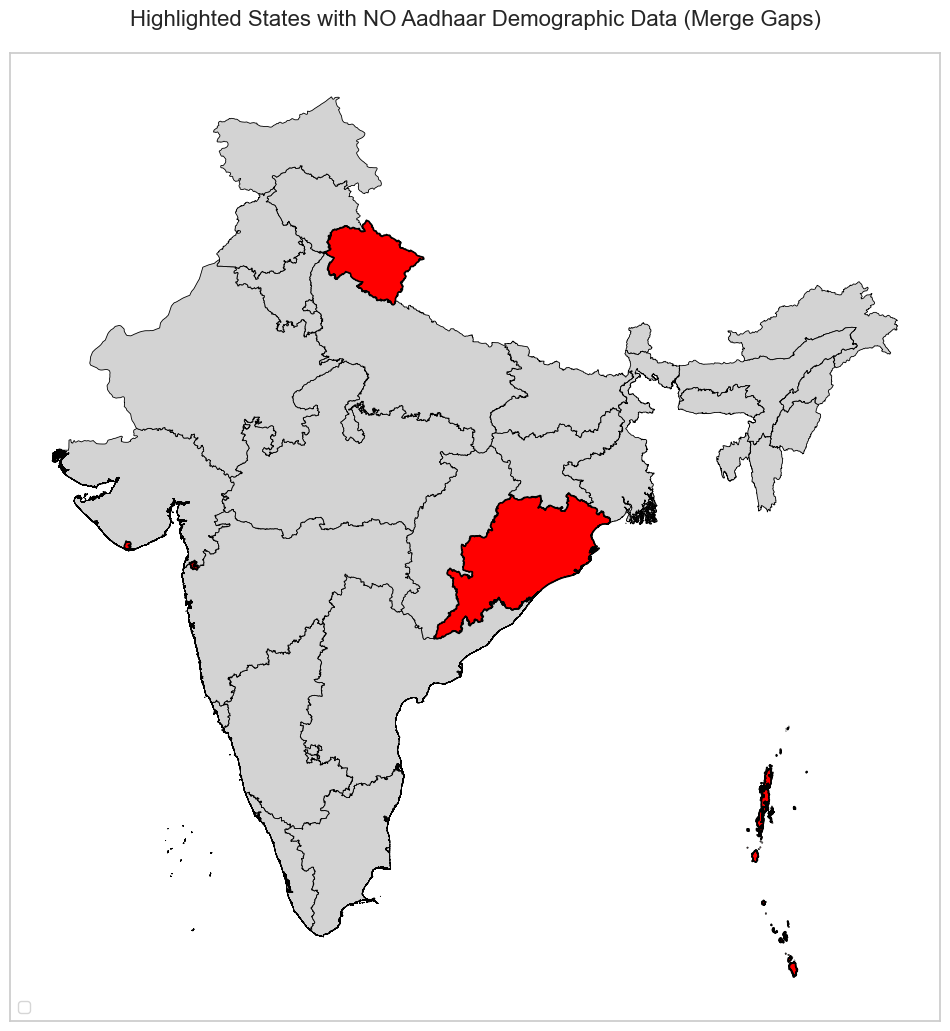

In [74]:
import geopandas as gpd
import matplotlib.pyplot as plt

# -------------------------------
# Create the figure
# -------------------------------
fig, ax = plt.subplots(figsize=(12, 14))

# -------------------------------
# Plot complete India map (background)
# -------------------------------
india_merged.plot(
    ax=ax,
    color='lightgrey',
    edgecolor='black',
    linewidth=0.6
)

# -------------------------------
# Highlight missing-data states
# -------------------------------
missing_states = india_merged[india_merged['total_updates'] == 0]

missing_states.plot(
    ax=ax,
    color='red',
    edgecolor='black',
    linewidth=1.2,
    label='Missing Aadhaar Data'
)

# -------------------------------
# Title & formatting
# -------------------------------
ax.set_title(
    "Highlighted States with NO Aadhaar Demographic Data (Merge Gaps)",
    fontsize=16,
    pad=20
)

ax.set_xticks([])
ax.set_yticks([])

# Optional legend
ax.legend(loc='lower left')

plt.show()


In [75]:
df_clean

,date,state,district,pincode,demo_age_5_17,demo_age_17_,total_updates,state_clean
0,2025-03-01,Uttar Pradesh,Gorakhpur,273213,49,529,578,Uttar Pradesh
1,2025-03-01,Andhra Pradesh,Chittoor,517132,22,375,397,Andhra Pradesh
2,2025-03-01,Gujarat,Rajkot,360006,65,765,830,Gujarat
3,2025-03-01,Andhra Pradesh,Srikakulam,532484,24,314,338,Andhra Pradesh
4,2025-03-01,Rajasthan,Udaipur,313801,45,785,830,Rajasthan
...,...,...,...,...,...,...,...,...
2071693,2025-12-29,West Bengal,West Midnapore,721212,0,12,12,West Bengal
2071694,2025-12-29,West Bengal,West Midnapore,721420,0,1,1,West Bengal
2071695,2025-12-29,West Bengal,West Midnapore,721424,0,5,5,West Bengal
2071696,2025-12-29,West Bengal,West Midnapore,721426,0,3,3,West Bengal


In [76]:
df_state = (
    df_clean
    .groupby('state_clean', as_index=False)['total_updates']
    .sum()
)

df_state['state_clean'] = df_state['state_clean'].str.strip().str.title()

In [77]:
india_states['state_shp'] = (
    india_states['state_shp']
    .str.strip()
    .str.title()
)

In [78]:
state_name_mapping = {
    'Orissa': 'Odisha',
    'Uttaranchal': 'Uttarakhand',
    'Andaman And Nicobar': 'Andaman And Nicobar Islands',
    'Dadra And Nagar Haveli': 'Dadra And Nagar Haveli And Daman And Diu',
    'Daman And Diu': 'Dadra And Nagar Haveli And Daman And Diu'
}

india_states['state_shp'] = india_states['state_shp'].replace(state_name_mapping)

In [79]:
india_merged = india_states.merge(
    df_state,
    left_on='state_shp',
    right_on='state_clean',
    how='left'
)

india_merged['total_updates'] = india_merged['total_updates'].fillna(0)

In [80]:
print("States in shapefile:", india_states['state_shp'].nunique())
print(
    "States with Aadhaar data:",
    india_merged[india_merged['total_updates'] > 0]['state_shp'].nunique()
)

unmatched = india_merged[india_merged['total_updates'] == 0]['state_shp'].unique()
print("Unmatched / Zero-data states:", unmatched)

States in shapefile: 34
States with Aadhaar data: 34
Unmatched / Zero-data states: []


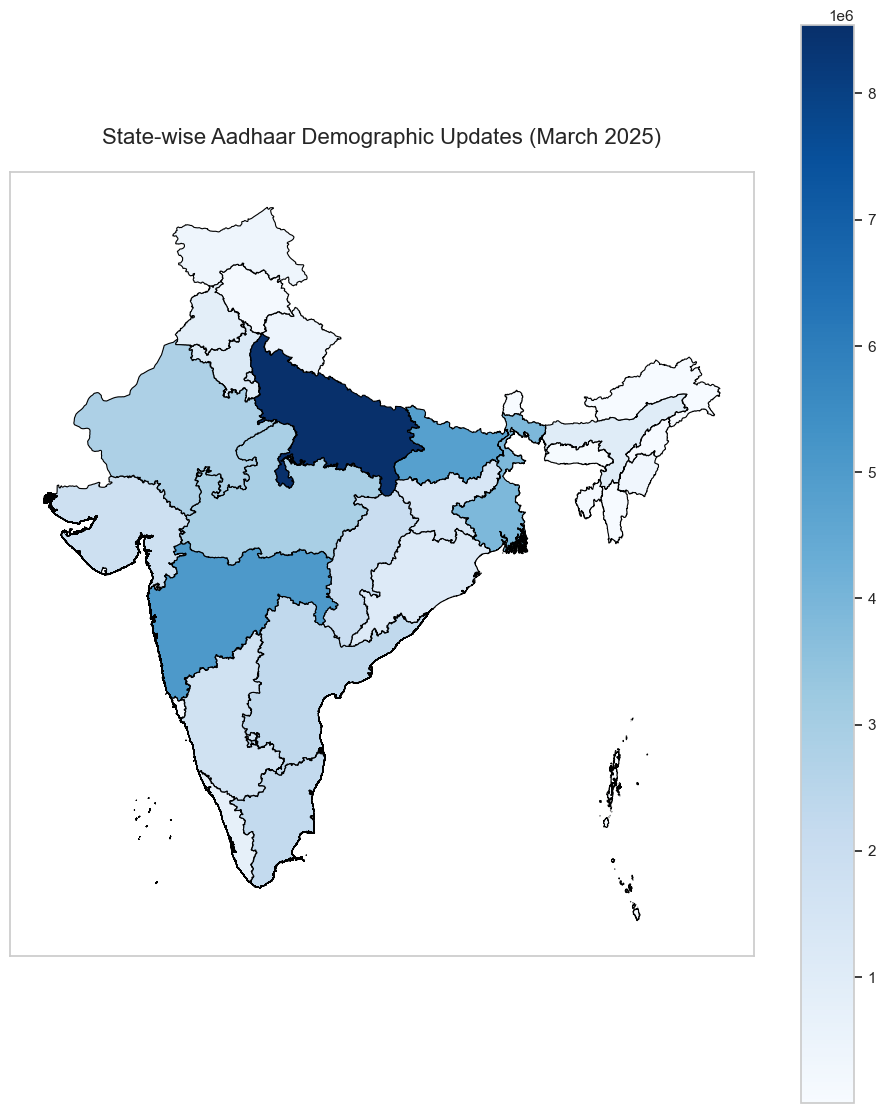

In [83]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 14))

india_merged.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='black',
    legend=True,
    ax=ax
)

ax.set_title(
    "State-wise Aadhaar Demographic Updates (March 2025)",
    fontsize=16,
    pad=20
)

ax.set_xticks([])
ax.set_yticks([])

plt.show()

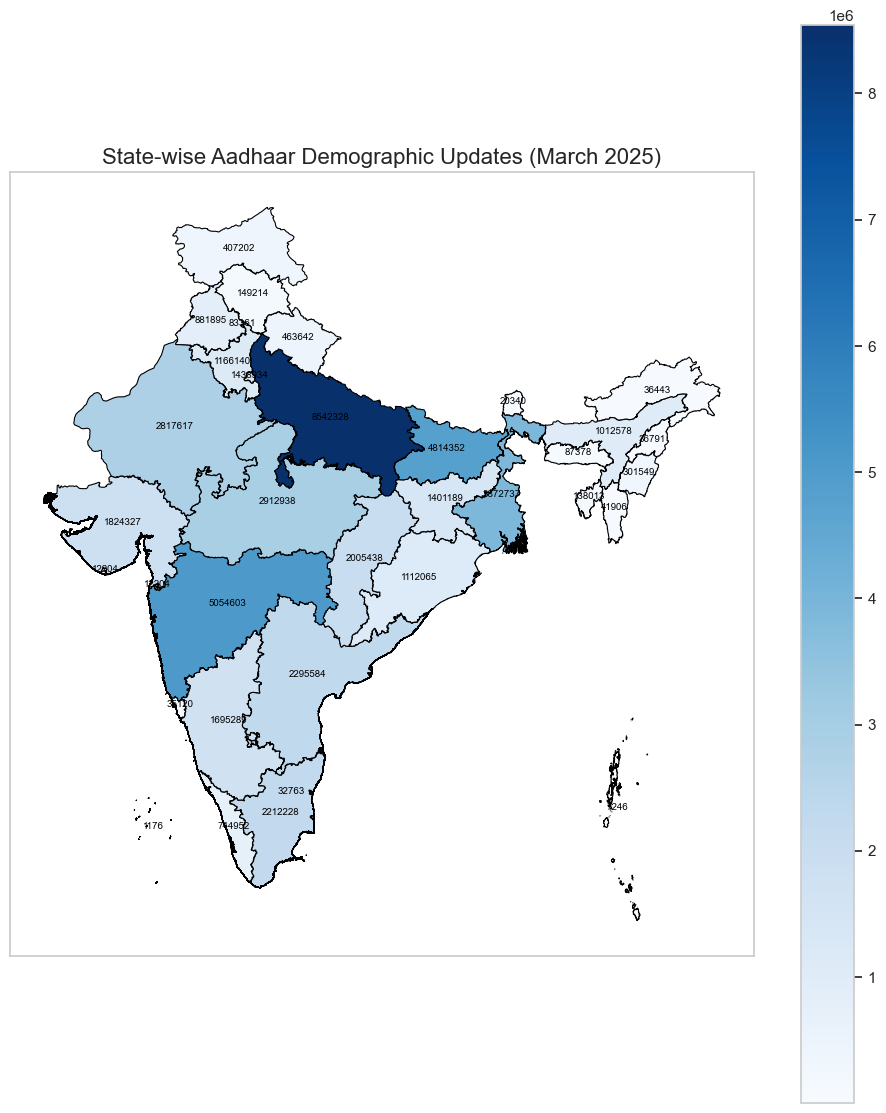

In [84]:

fig, ax = plt.subplots(figsize=(12, 14))

india_merged.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='black',
    legend=True,
    ax=ax
)

ax.set_title(
    "State-wise Aadhaar Demographic Updates (March 2025)",
    fontsize=16
)

ax.set_xticks([])
ax.set_yticks([])

# ---- ADD VALUE LABELS ON MAP ----
for idx, row in india_merged.iterrows():
    if row['total_updates'] > 0:
        ax.text(
            row.geometry.centroid.x,
            row.geometry.centroid.y,
            f"{int(row['total_updates'])}",
            horizontalalignment='center',
            fontsize=7,
            color='black'
        )

plt.show()

In [85]:
plot_df = india_merged[['state_shp', 'total_updates']].copy()

plot_df = plot_df.sort_values(
    by='total_updates',
    ascending=False
).reset_index(drop=True)

print("State-wise Aadhaar Updates (Used for Plotting):")
print(plot_df)

print("\nTotal states in plot dataframe:", len(plot_df))

State-wise Aadhaar Updates (Used for Plotting):
                                   state_shp  total_updates
0                              Uttar Pradesh        8542328
1                                Maharashtra        5054603
2                                      Bihar        4814352
3                                West Bengal        3872737
4                             Madhya Pradesh        2912938
5                                  Rajasthan        2817617
6                             Andhra Pradesh        2295584
7                                 Tamil Nadu        2212228
8                               Chhattisgarh        2005438
9                                    Gujarat        1824327
10                                 Karnataka        1695289
11                                     Delhi        1438934
12                                 Jharkhand        1401189
13                                   Haryana        1166140
14                                    Odisha        

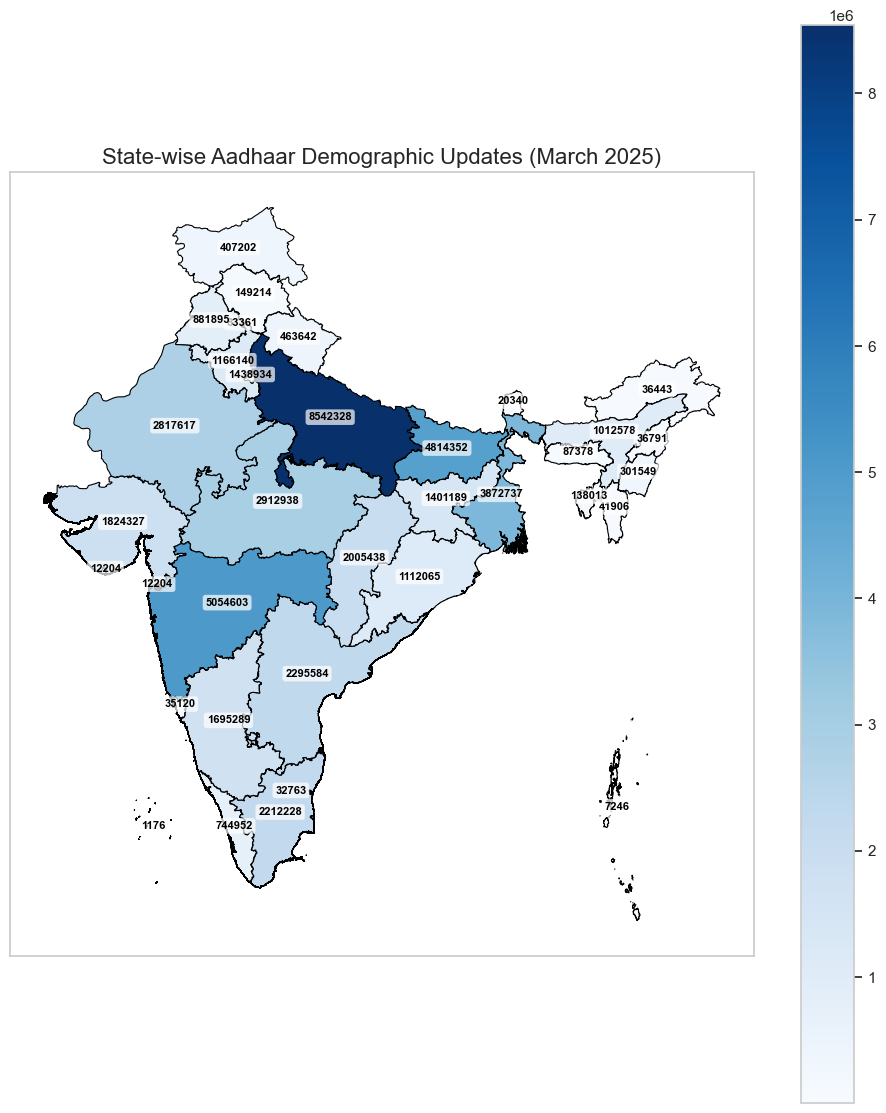

In [87]:
fig, ax = plt.subplots(figsize=(12, 14))

india_merged.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='black',
    legend=True,
    ax=ax
)

ax.set_title(
    "State-wise Aadhaar Demographic Updates (March 2025)",
    fontsize=16
)

ax.set_xticks([])
ax.set_yticks([])

# ---- ADD HIGHLIGHTED VALUE LABELS ON MAP ----
for idx, row in india_merged.iterrows():
    if row['total_updates'] > 0:
        ax.text(
            row.geometry.centroid.x,
            row.geometry.centroid.y,
            f"{int(row['total_updates'])}",
            horizontalalignment='center',
            fontsize=8,
            fontweight='bold',
            color='black',
            bbox=dict(
                facecolor='white',
                edgecolor='none',
                alpha=0.7,
                boxstyle='round,pad=0.25'
            )
        )

plt.show()


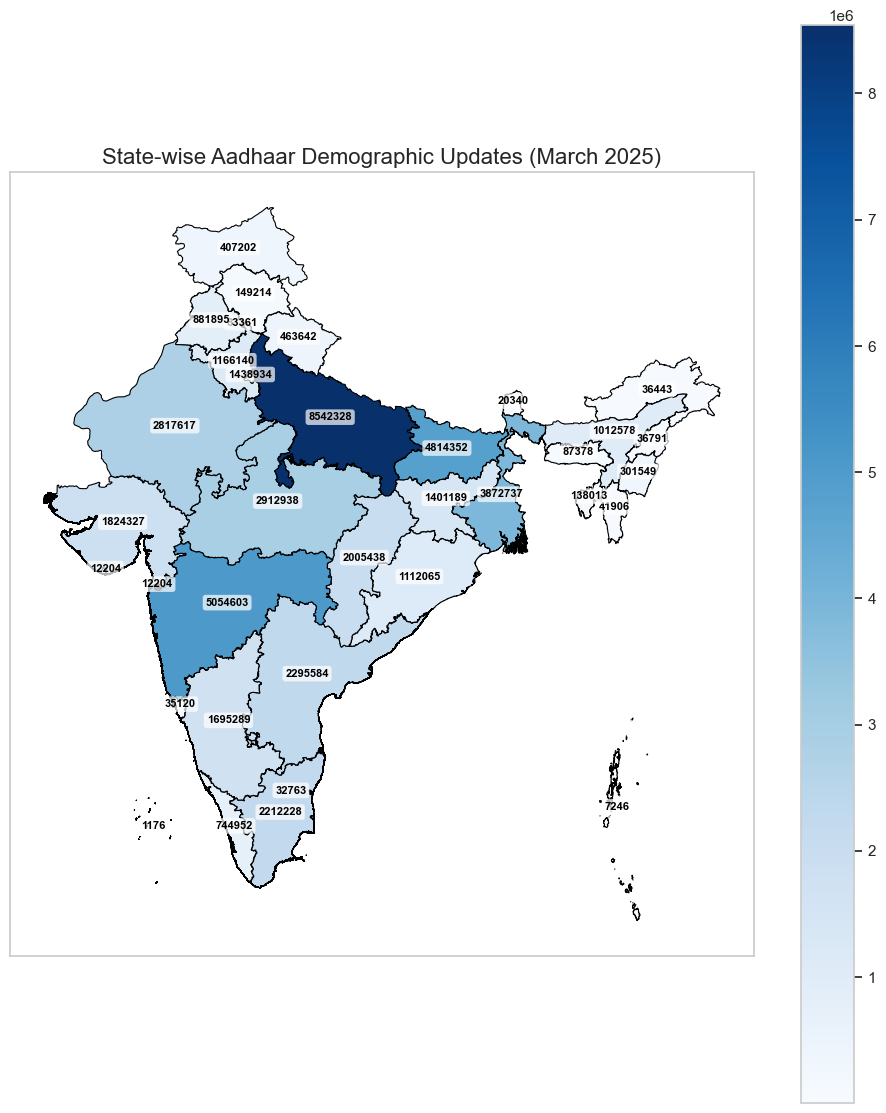

In [88]:
fig, ax = plt.subplots(figsize=(12, 14))

india_merged.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='black',
    legend=True,
    ax=ax
)

ax.set_title(
    "State-wise Aadhaar Demographic Updates (March 2025)",
    fontsize=16
)

ax.set_xticks([])
ax.set_yticks([])

# ---- ADD HIGHLIGHTED VALUE LABELS ON MAP ----
for idx, row in india_merged.iterrows():
    if row['total_updates'] > 0:
        ax.text(
            row.geometry.centroid.x,
            row.geometry.centroid.y,
            f"{int(row['total_updates'])}",
            horizontalalignment='center',
            fontsize=8,
            fontweight='bold',
            color='black',
            bbox=dict(
                facecolor='white',
                edgecolor='none',
                alpha=0.7,
                boxstyle='round,pad=0.25'
            )
        )

plt.show()


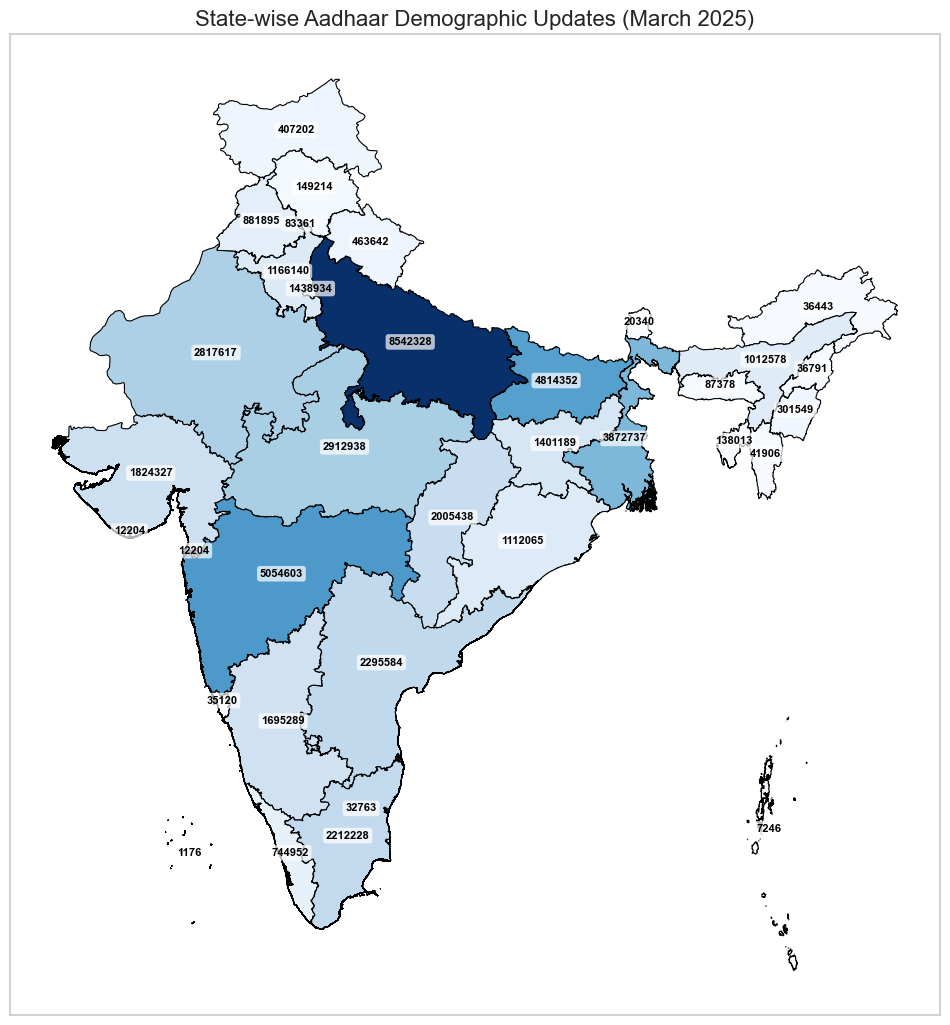

In [89]:
fig, ax = plt.subplots(figsize=(12, 14))
india_merged.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='black',
    legend=False,  # Changed from True to False
    ax=ax
)
ax.set_title(
    "State-wise Aadhaar Demographic Updates (March 2025)",
    fontsize=16
)
ax.set_xticks([])
ax.set_yticks([])
# ---- ADD HIGHLIGHTED VALUE LABELS ON MAP ----
for idx, row in india_merged.iterrows():
    if row['total_updates'] > 0:
        ax.text(
            row.geometry.centroid.x,
            row.geometry.centroid.y,
            f"{int(row['total_updates'])}",
            horizontalalignment='center',
            fontsize=8,
            fontweight='bold',
            color='black',
            bbox=dict(
                facecolor='white',
                edgecolor='none',
                alpha=0.7,
                boxstyle='round,pad=0.25'
            )
        )
plt.show()

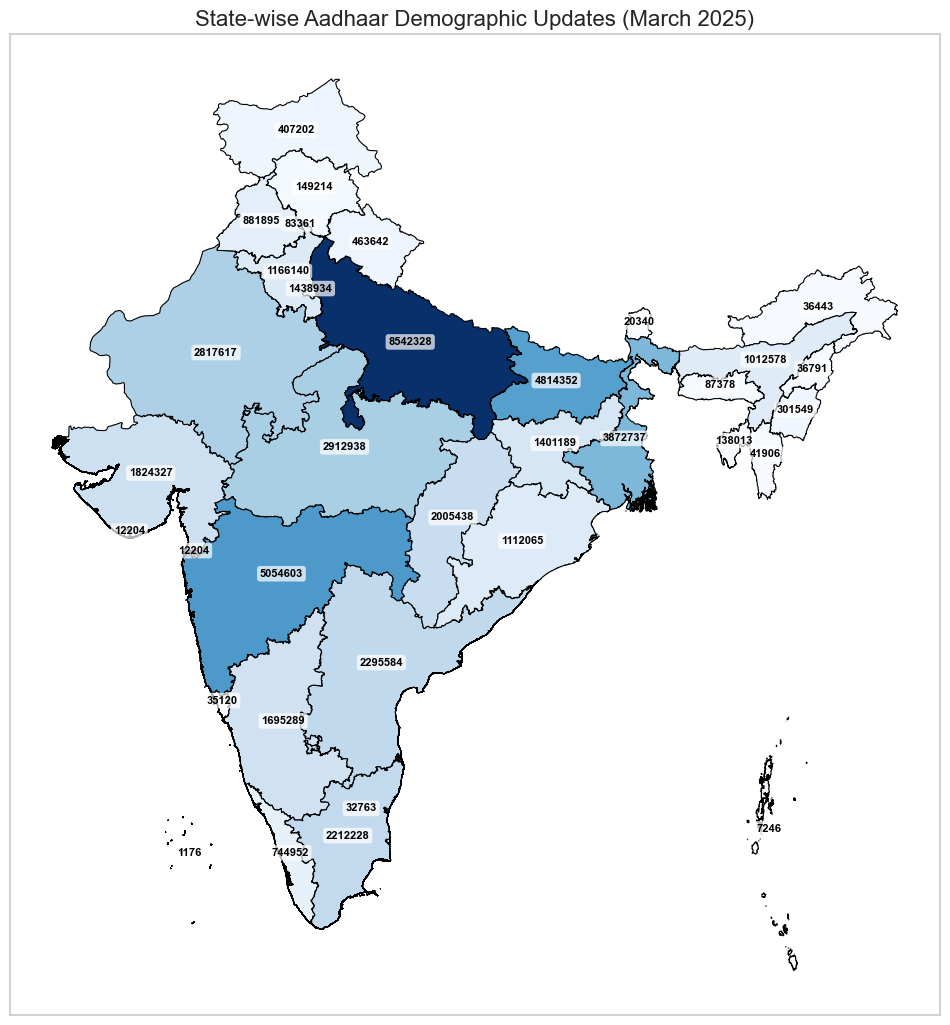

In [90]:
fig, ax = plt.subplots(figsize=(12, 14))
india_merged.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='black',
    legend=False,  # Changed from True to False
    ax=ax
)
ax.set_title(
    "State-wise Aadhaar Demographic Updates (March 2025)",
    fontsize=16
)
ax.set_xticks([])
ax.set_yticks([])
# ---- ADD HIGHLIGHTED VALUE LABELS ON MAP ----
for idx, row in india_merged.iterrows():
    if row['total_updates'] > 0:
        ax.text(
            row.geometry.centroid.x,
            row.geometry.centroid.y,
            f"{int(row['total_updates'])}",
            horizontalalignment='center',
            fontsize=8,
            fontweight='bold',
            color='black',
            bbox=dict(
                facecolor='white',
                edgecolor='none',
                alpha=0.7,
                boxstyle='round,pad=0.25'
            )
        )
plt.show()

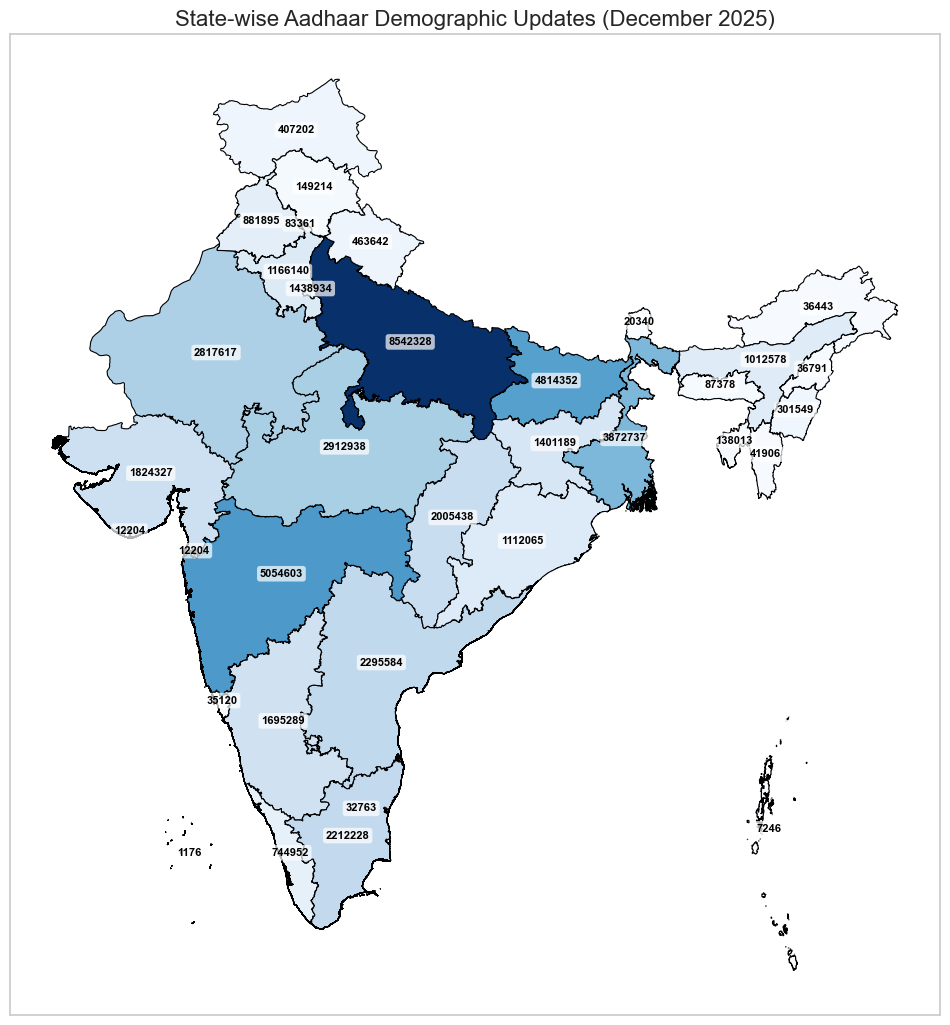

In [91]:
fig, ax = plt.subplots(figsize=(12, 14))
india_merged.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='black',
    legend=False,  # Changed from True to False
    ax=ax
)
ax.set_title(
    "State-wise Aadhaar Demographic Updates (December 2025)",
    fontsize=16
)
ax.set_xticks([])
ax.set_yticks([])
# ---- ADD HIGHLIGHTED VALUE LABELS ON MAP ----
for idx, row in india_merged.iterrows():
    if row['total_updates'] > 0:
        ax.text(
            row.geometry.centroid.x,
            row.geometry.centroid.y,
            f"{int(row['total_updates'])}",
            horizontalalignment='center',
            fontsize=8,
            fontweight='bold',
            color='black',
            bbox=dict(
                facecolor='white',
                edgecolor='none',
                alpha=0.7,
                boxstyle='round,pad=0.25'
            )
        )
plt.show()

In [94]:
import pandas as pd
import geopandas as gpd

# ---------------------------------
# 1. Filter Maharashtra from df_clean
# ---------------------------------

maha_df = df_clean[df_clean['state_clean'] == 'Maharashtra'].copy()

print("Rows in Maharashtra data:", len(maha_df))
print(maha_df.head())

# ---------------------------------
# 2. Aggregate Total Updates District-wise
# ---------------------------------

maha_district_updates = (
    maha_df
    .groupby('district')['total_updates']
    .sum()
    .reset_index()
)

print("\nDistrict-wise Maharashtra Summary:")
print(maha_district_updates.head())
print("Total Districts in Data:", len(maha_district_updates))

# ---------------------------------
# 3. Load Maharashtra District Shapefile
# ---------------------------------

shapefile_path = r"C:/Users/Yash/Desktop/Aanchal/india/IND_adm2.shp"
india_districts = gpd.read_file(shapefile_path)

# Filter only Maharashtra from shapefile
maharashtra_shp = india_districts[india_districts['NAME_1'] == 'Maharashtra'].copy()

print("\nTotal Districts in Shapefile:", len(maharashtra_shp))
print(maharashtra_shp[['NAME_2']].head())

# ---------------------------------
# 4. Clean District Names for Matching
# ---------------------------------

# Clean names in data
maha_district_updates['district_clean'] = maha_district_updates['district'].str.strip().str.lower()

# Clean names in shapefile
maharashtra_shp['district_clean'] = maharashtra_shp['NAME_2'].str.strip().str.lower()

# ---------------------------------
# 5. Merge to Create Final Maharashtra District DataFrame
# ---------------------------------

maha_final_df = maharashtra_shp.merge(
    maha_district_updates,
    on='district_clean',
    how='left'
)

# Fill districts with no data as 0
maha_final_df['total_updates'] = maha_final_df['total_updates'].fillna(0)

# Rename for clarity
maha_final_df = maha_final_df.rename(columns={
    'NAME_1': 'state',
    'NAME_2': 'district'
})

# Select only required columns
maha_final_df = maha_final_df[['state', 'district', 'total_updates']]

print("\nFinal Maharashtra District DataFrame:")
print(maha_final_df)
print("Total Districts Final:", len(maha_final_df))


Rows in Maharashtra data: 162243
          date        state district  pincode  demo_age_5_17  demo_age_17_  \
15  2025-03-01  Maharashtra   Nashik   422305             13           227   
29  2025-03-01  Maharashtra  Jalgaon   425310             30           685   
84  2025-03-01  Maharashtra   Nagpur   440007             10            57   
110 2025-03-01  Maharashtra   Mumbai   400097             28           675   
152 2025-03-01  Maharashtra  Solapur   413214             22           331   

     total_updates  state_clean  
15             240  Maharashtra  
29             715  Maharashtra  
84              67  Maharashtra  
110            703  Maharashtra  
152            353  Maharashtra  

District-wise Maharashtra Summary:
      district  total_updates
0  Ahilyanagar           2418
1   Ahmadnagar         227667
2  Ahmed Nagar           5595
3        Akola          62082
4     Amravati          96191
Total Districts in Data: 54


DataSourceError: C:/Users/Yash/Desktop/Aanchal/india/IND_adm2.shp: No such file or directory

In [98]:
maha_df.columns

Index(['date', 'state', 'district', 'pincode', 'demo_age_5_17', 'demo_age_17_',
       'total_updates', 'state_clean'],
      dtype='object')

In [99]:
maha_df

,date,state,district,pincode,demo_age_5_17,demo_age_17_,total_updates,state_clean
15,2025-03-01,Maharashtra,Nashik,422305,13,227,240,Maharashtra
29,2025-03-01,Maharashtra,Jalgaon,425310,30,685,715,Maharashtra
84,2025-03-01,Maharashtra,Nagpur,440007,10,57,67,Maharashtra
110,2025-03-01,Maharashtra,Mumbai,400097,28,675,703,Maharashtra
152,2025-03-01,Maharashtra,Solapur,413214,22,331,353,Maharashtra
...,...,...,...,...,...,...,...,...
2065027,2025-12-28,Maharashtra,Yavatmal,445206,2,18,20,Maharashtra
2065028,2025-12-28,Maharashtra,Yavatmal,445211,0,1,1,Maharashtra
2065029,2025-12-28,Maharashtra,Yavatmal,445215,0,24,24,Maharashtra
2065030,2025-12-28,Maharashtra,Yavatmal,445216,0,1,1,Maharashtra


In [ ]:
maha_df.head(10)

In [ ]:
import matplotlib.pyplot as plt

# ---------------------------------
# 1. Use Your Clean maha_final_df
# ---------------------------------

# Safety: remove duplicate columns if any
maha_final_df = maha_df.loc[:, ~maha_df.columns.duplicated()]

# Sort by total_updates (descending)
maha_bar_df = maha_df.sort_values(by='total_updates', ascending=False).reset_index(drop=True)

print("Top 10 Maharashtra Districts by Total Updates:")
print(maha_bar_df.head(10))

# ---------------------------------
# 2. Create Bar Plot
# ---------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(
    maha_bar_df['district'],
    maha_bar_df['total_updates']
)

ax.set_title("Maharashtra District-wise Total Updates", fontsize=16)
ax.set_xlabel("District", fontsize=12)
ax.set_ylabel("Total Updates", fontsize=12)

# Rotate district names for readability
plt.xticks(rotation=90)

# ---------------------------------
# 3. Add Value Labels on Top of Bars (Optional but Recommended)
# ---------------------------------

for idx, value in enumerate(maha_bar_df['total_updates']):
    if value > 0:
        ax.text(
            idx,
            value,
            f"{int(value)}",
            ha='center',
            va='bottom',
            fontsize=8,
            rotation=90
        )

plt.tight_layout()
plt.show()


Total districts in shapefile: 34


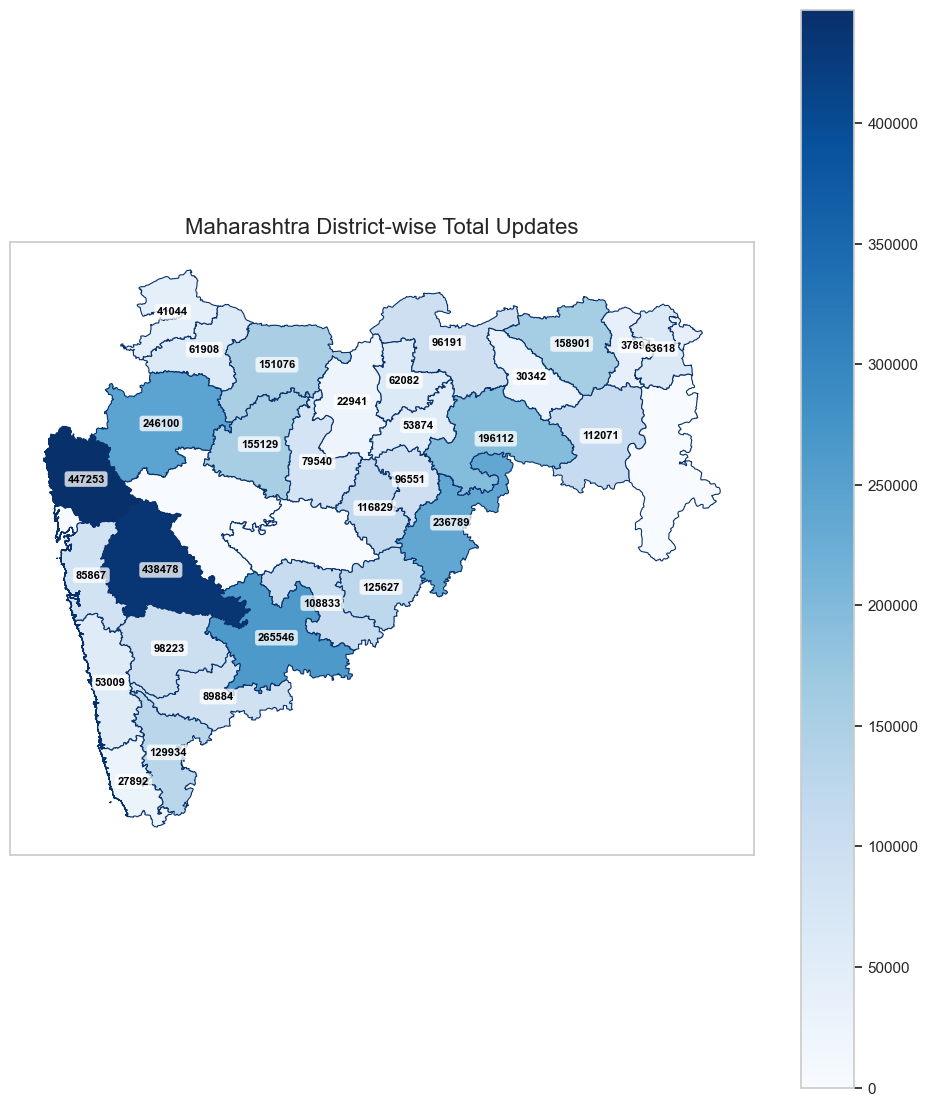

In [106]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# ---------------------------------
# 1. Maharashtra District Data
# ---------------------------------

maha_df = pd.DataFrame({
    "state": ["Maharashtra"] * 34,
    "district": [
        "Ahmednagar","Akola","Amravati","Aurangabad","Bhandara","Bid","Buldana",
        "Chandrapur","Dhule","Garhchiroli","Gondiya","Greater Bombay","Hingoli",
        "Jalgaon","Jalna","Kolhapur","Latur","Nagpur","Nanded","Nandurbar",
        "Nashik","Osmanabad","Parbhani","Pune","Raigarh","Ratnagiri","Sangli",
        "Satara","Sindhudurg","Solapur","Thane","Wardha","Washim","Yavatmal"
    ],
    "total_updates": [
        0,62082,96191,155129,37894,11918,22941,112071,61908,0,63618,0,
        96551,151076,79540,129934,125627,158901,236789,41044,246100,
        108833,116829,438478,85867,53009,89884,98223,27892,265546,
        447253,30342,53874,196112
    ]
})

# ---------------------------------
# 2. Load District Shapefile
# ---------------------------------

shapefile_path = r"C:\Users\ASUS\OneDrive\Documents\Desktop\Aanchal\india\IND_adm2.shp"
india_districts = gpd.read_file(shapefile_path)

# Case-safe Maharashtra filter
maharashtra_shp = india_districts[
    india_districts['NAME_1'].str.lower() == 'maharashtra'
].copy()

print("Total districts in shapefile:", len(maharashtra_shp))

# ---------------------------------
# 3. Clean & Fix District Names
# ---------------------------------

maha_df['district_clean'] = maha_df['district'].str.strip().str.lower()
maharashtra_shp['district_clean'] = maharashtra_shp['NAME_2'].str.strip().str.lower()

# Fix common name mismatches
name_fix = {
    'greater bombay': 'mumbai',
    'bid': 'beed',
    'garhchiroli': 'gadchiroli'
}

maha_df['district_clean'] = maha_df['district_clean'].replace(name_fix)

# ---------------------------------
# 4. Merge Data with Geometry
# ---------------------------------

maha_geo = maharashtra_shp.merge(
    maha_df,
    on='district_clean',
    how='left'
)

maha_geo['total_updates'] = maha_geo['total_updates'].fillna(0)

# ---------------------------------
# 5. Fix Geometry & CRS
# ---------------------------------

maha_geo = gpd.GeoDataFrame(
    maha_geo,
    geometry='geometry',
    crs=maharashtra_shp.crs
)

# Fix invalid geometries
maha_geo['geometry'] = maha_geo['geometry'].buffer(0)

# ---------------------------------
# 6. Plot Blue Heatmap Choropleth
# ---------------------------------

fig, ax = plt.subplots(figsize=(12, 14))
ax.set_title("Maharashtra District-wise Total Updates", fontsize=16)

maha_geo.plot(
    column='total_updates',
    cmap='Blues',
    linewidth=0.8,
    edgecolor='#08306b',
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "#deebf7",
        "label": "No Data"
    }
)

# ---------------------------------
# 7. Add Labels (Counts)
# ---------------------------------

for _, row in maha_geo.iterrows():
    if row.geometry is not None and row['total_updates'] > 0:
        c = row.geometry.centroid
        ax.text(
            c.x, c.y,
            f"{int(row['total_updates'])}",
            ha='center',
            va='center',
            fontsize=8,
            fontweight='bold',
            color='black',
            bbox=dict(
                facecolor='white',
                edgecolor='none',
                alpha=0.75,
                boxstyle='round,pad=0.25'
            )
        )

# ---------------------------------
# 8. Clean Map View
# ---------------------------------

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

plt.show()

# ---------------------------------
# 9. Optional Save
# ---------------------------------
# plt.savefig("maharashtra_district_heatmap.png", dpi=300, bbox_inches="tight")
